<a href="https://colab.research.google.com/github/AGMATICABR/meteorologia/blob/main/ROSA_DOS_VENTOS_METAR_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Rosa dos Ventos a partir de dados mensagem METAR<br>
METAR (Meteorological Aerodrome Report) é um formato de mensagem para reportar as informações meteorológicas, tipicamente usado na aviação. Ela contém vários parâmetros meteorológicos, incluindo direção e velocidade do vento para plotar o gráfico da Rosa dos Ventos. A seguir, o passo a passo!

**Formatação da mensagem e upload**<br>

a) **Gerar o arquivo**<br>
<span style="font-size: 8px; color: purple; line-height: 1;">
Baixar a mensagem METAR (https://redemet.decea.mil.br/); abrir o Bloco de Notas, edite a mensagem e salve na extensão ".TXT"

b) **Layout da mensagem**<br>
<span style="font-size: 8px; color: purple; line-height: 1;">
A biblioteca Metar, que é usada para analisar as mensagens meteorológicas, funciona de forma mais eficaz quando a string de entrada não inclui o prefixo "METAR ". A remoção desse prefixo ajuda a biblioteca a processar corretamente os dados subsequentes, como o código ICAO, data-hora e parâmetros meteorológicos, sem se "confundir".
Exemplo:<br>
SBFL 161100Z 01012KT 5000 BR BKN008 BKN020 20/19 Q1020=<br>
SBFL 161200Z 01011KT 5000 -DZ BKN008 BKN020 20/20 Q1021=<br>
SBFL 161224Z 01011KT 9999 BKN014 BKN030 21/20 Q1021=<br>
(...)

c) **Upload de Arquivo**<br>
Após executar a célula, uma caixa de diálogo `Escolher arquivos` se abrirá no seu rodapé, selecionar o arquivo (mensagem METAR) salvo no computador para upload ao Google Colab.<br>

In [ ]:
#=============================================================================
# 1º INSTALAR E IMPORTAR BIBLIOTECAS
# =============================================================================
# Instalação e importação das bibliotecas e módulos do Python necessários
# para todo o processo de análise e visualização dos parâmetros meteorologios
# da mensagem METAR.⛔NÃO Altere! ▶ Execute!
# ----------------------------------------------------------------------------

!pip install metar
!pip install windrose
from metar import Metar
import windrose as wr
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#=============================================================================
# 2º UPLOAD DO ARQUIVO METAR
#============================================================================
# Ao executar esta célula, uma caixa de diálogo "Escolher arquivos" se abrirá
# no seu rodapé desta célula para selecionar o arquivo (mensagem METAR) no
# computador e assim fazer o upload ao Google Colab.
# ⛔ NÃO Altere! ▶ Execute!
#----------------------------------------------------------------------------

from google.colab import files
import io

uploaded = files.upload()

for filename in uploaded.keys():
    print(f'Usuário carregou o arquivo "{filename}" com tamanho {len(uploaded[filename])} bytes')

    with open(filename, 'wb') as f:
        f.write(uploaded[filename])

    print(f'Arquivo "{filename}" salvo em /content/{filename}')

    global file_path
    file_path = f'/content/{filename}'
    print(f'file_path atualizado para: {file_path}')
    break

Saving METAR SBFL 16082026.txt to METAR SBFL 16082026 (1).txt
Usuário carregou o arquivo "METAR SBFL 16082026 (1).txt" com tamanho 1235 bytes
Arquivo "METAR SBFL 16082026 (1).txt" salvo em /content/METAR SBFL 16082026 (1).txt
file_path atualizado para: /content/METAR SBFL 16082026 (1).txt


In [ ]:
#=============================================================================
# 3º PROCESSAMENTO DO ARQUIVO METAR
#============================================================================
# Ao executar esta célula, o arquivo que acabou de ser carregado via uploado
# será precessado  e identificará os registros de vento (direção e velocidade)
# ⛔ NÃO Altere! ▶ Execute!
#----------------------------------------------------------------------------

from metar import Metar
import os

# Reinicializa as listas para cada nova execução
file_vel = []
file_dir = []
icao_code = None
report_date = None
first_metar_processed = False

# Determina o arquivo a ser processado
try:
    if 'file_path' in globals() and os.path.exists(file_path):
        current_file = file_path
    else:
        current_file = '/content/METAR_SBFL_20260816.txt'

    if not os.path.exists(current_file):
        raise FileNotFoundError(f"Arquivo {current_file} não encontrado.")

    print(f"Lendo dados de: {current_file}\n")

    with open(current_file, 'r') as f:
        for i, line in enumerate(f):
            full_line = line.strip()
            if not full_line:
                continue

            # Busca o código ICAO da estação
            start_idx = full_line.find('SBFL')
            if start_idx != -1:
                metar_msg = full_line[start_idx:].strip()
                try:
                    obs = Metar.Metar(metar_msg)
                    if obs.wind_dir and obs.wind_speed:
                        file_vel.append(obs.wind_speed.value())
                        file_dir.append(obs.wind_dir.value())

                        if not first_metar_processed:
                            icao_code = obs.station_id
                            report_date = obs.time.strftime('%d/%m/%Y') if obs.time else "N/A"
                            first_metar_processed = True
                except Exception:
                    continue

    print(f"Processamento concluído: {len(file_vel)} registros de vento encontrados.")

except Exception as e:
    print(f"Erro no processamento: {e}")
    print("Dica: Certifique-se de ter executado a célula de upload com sucesso.")

Lendo dados de: /content/METAR SBFL 16082026 (1).txt

Processamento concluído: 21 registros de vento encontrados.


Gerando Rosa dos Ventos para SBFL em 16/08/2026...
Gráfico salvo com sucesso como: rosa_dos_ventos_SBFL.png


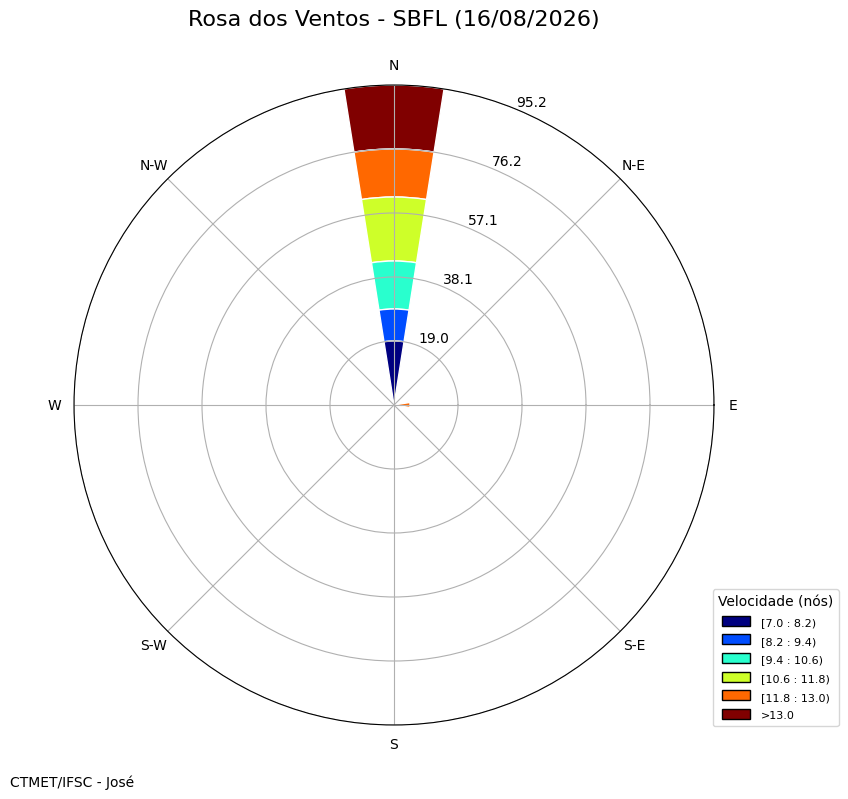

In [ ]:
#=============================================================================
# 4º GERA GRÁFICO ROSA DOS VENTOS
#============================================================================
# Gera a Rosa dos ventos com os dados processados da mensagem METAR.
# ⛔ NÃO Altere! ▶ Execute!
#----------------------------------------------------------------------------
import matplotlib.cm as cm
import windrose as wr
import numpy as np
import matplotlib.pyplot as plt

# Acessa as variáveis geradas no processamento
global file_vel, file_dir, icao_code, report_date

# Verifica existencia de dados para plotar
if 'file_vel' in globals() and len(file_vel) > 0:
    print(f"Gerando Rosa dos Ventos para {icao_code} em {report_date}...")

    # Cria o gráfico
    fig = plt.figure(figsize=(8, 8), dpi=100)
    ax = wr.WindroseAxes.from_ax(fig=fig)
    ax.bar(file_dir, file_vel, normed=True, opening=0.8, edgecolor='white', cmap=cm.jet)
    # Usou a frequências percentual verdadeira

    # Título
    title_str = f'Rosa dos Ventos - {icao_code}'
    if report_date:
        title_str += f' ({report_date})'
    ax.set_title(title_str, fontsize=16, y=1.08)

    # Legenda
    ax.set_legend(title="Velocidade (nós)", loc='lower left', bbox_to_anchor=(1, 0))
    # Nota
    plt.figtext(0.02, 0.02, 'CTMET/IFSC - José', fontsize=10, ha='left', va='bottom')

    # Salva o gráfico como PNG transparente
    filename_save = f'rosa_dos_ventos_{icao_code}.png'
    plt.savefig(filename_save, transparent=True, bbox_inches='tight')
    print(f"Gráfico salvo com sucesso como: {filename_save}")

    plt.show()
else:
    print("Erro: Não há dados de vento disponíveis.")